**A. Implementation of Support Vector Machines (SVM) for classifying images of hand-written digits into their respective numerical classes (0 to 9).**

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,ConfusionMatrixDisplay

In [5]:
digits=load_digits()

In [6]:
digits

{'data': array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  2., ..., 12.,  0.,  0.],
        [ 0.,  0., 10., ..., 12.,  1.,  0.]], shape=(1797, 64)),
 'target': array([0, 1, 2, ..., 8, 9, 8], shape=(1797,)),
 'frame': None,
 'feature_names': ['pixel_0_0',
  'pixel_0_1',
  'pixel_0_2',
  'pixel_0_3',
  'pixel_0_4',
  'pixel_0_5',
  'pixel_0_6',
  'pixel_0_7',
  'pixel_1_0',
  'pixel_1_1',
  'pixel_1_2',
  'pixel_1_3',
  'pixel_1_4',
  'pixel_1_5',
  'pixel_1_6',
  'pixel_1_7',
  'pixel_2_0',
  'pixel_2_1',
  'pixel_2_2',
  'pixel_2_3',
  'pixel_2_4',
  'pixel_2_5',
  'pixel_2_6',
  'pixel_2_7',
  'pixel_3_0',
  'pixel_3_1',
  'pixel_3_2',
  'pixel_3_3',
  'pixel_3_4',
  'pixel_3_5',
  'pixel_3_6',
  'pixel_3_7',
  'pixel_4_0',
  'pixel_4_1',
  'pixel_4_2',
  'pixel_4_3',
  'pixel_4_4',
  'pixel_4_5',
  'pixel_4_6',
  'pixel_4_7'

In [7]:
x=digits.data
y=digits.target
x

x.shape
y.shape


(1797,)

In [8]:
np.unique(y)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

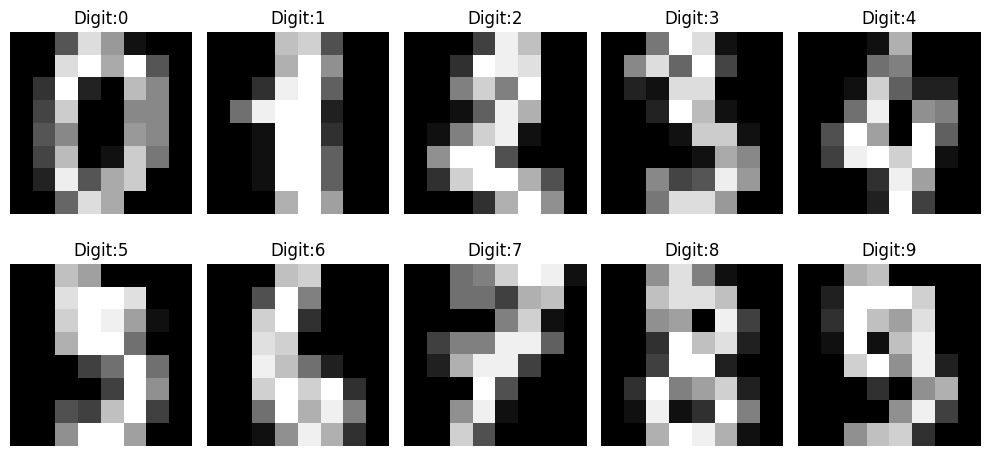

In [9]:
fig,axes=plt.subplots(2,5,figsize=(10,5))
for ax,image,label in zip(
    axes.ravel(),digits.images[:10],digits.target[:10]
):
    ax.imshow(image,cmap="gray")
    ax.set_title(f"Digit:{label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1437
Testing samples: 360


In [11]:
model=make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf",C=10,gamma="scale")

)
model.fit(X_train,y_train)


,steps,"[('standardscaler', ...), ('svc', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,C,10
,kernel,'rbf'
,degree,3
,gamma,'scale'


In [12]:
y_pred=model.predict(X_test)
print("ACTUAL DIGIT:",y_test[:10])
print("PREDICTED DIGIT:",y_test[:10])

ACTUAL DIGIT: [5 2 8 1 7 2 6 2 6 5]
PREDICTED DIGIT: [5 2 8 1 7 2 6 2 6 5]


In [14]:
accuracy=accuracy_score(y_test,y_pred)
accuracy

0.9805555555555555

In [15]:
classification_report(y_test,y_pred)

'              precision    recall  f1-score   support\n\n           0       1.00      1.00      1.00        36\n           1       0.97      0.97      0.97        36\n           2       1.00      1.00      1.00        35\n           3       1.00      1.00      1.00        37\n           4       0.95      0.97      0.96        36\n           5       0.97      1.00      0.99        37\n           6       0.97      1.00      0.99        36\n           7       0.95      0.97      0.96        36\n           8       1.00      0.94      0.97        35\n           9       1.00      0.94      0.97        36\n\n    accuracy                           0.98       360\n   macro avg       0.98      0.98      0.98       360\nweighted avg       0.98      0.98      0.98       360\n'

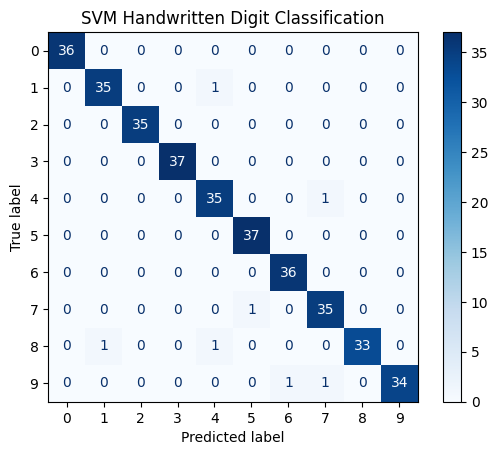

In [20]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap='Blues'
)
plt.title("SVM Handwritten Digit Classification")
plt.show()

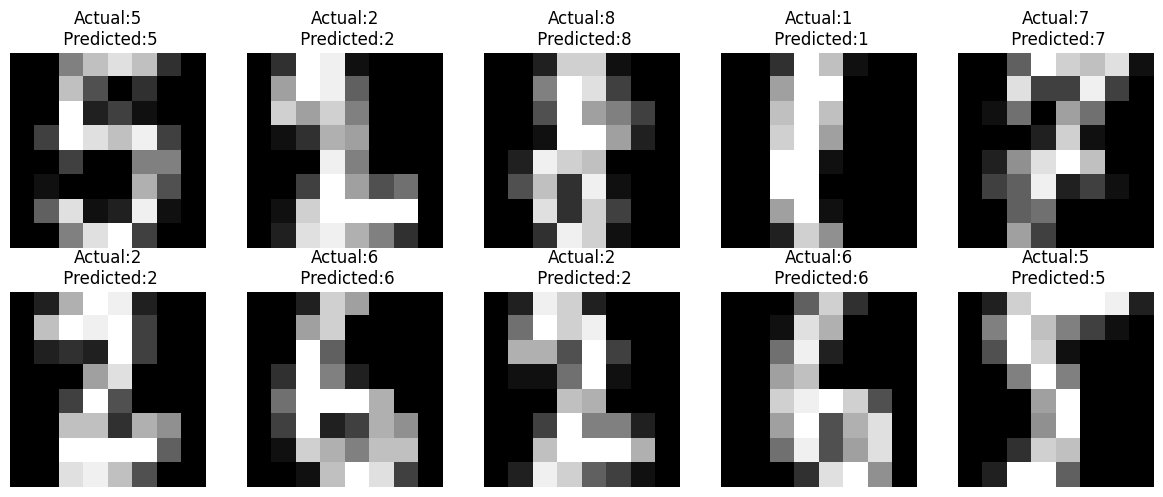

In [21]:
fig,axes=plt.subplots(2,5,figsize=(12,5))

for i,ax in enumerate(axes.ravel()):
    image=X_test[i].reshape(8,8)
    ax.imshow(image,cmap="gray")
    ax.set_title(
        f"Actual:{y_test[i]}\n Predicted:{y_pred[i]}"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()